--- Training Autoencoder on MNIST Digits ---
Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.3676 - val_loss: 0.3137
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.3041 - val_loss: 0.3015
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.2952 - val_loss: 0.2943
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.2903 - val_loss: 0.2900
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2865 - val_loss: 0.2872
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2840 - val_loss: 0.2851
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.2820 - val_loss: 0.2834
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.2805 - val_loss: 0.2819
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.2793 - val_loss: 0.2811
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.2782 - val_loss: 0.2800

--- Loading Local Alphabet Dataset for Testing ---
Error: Directory not found at ''

--- Test

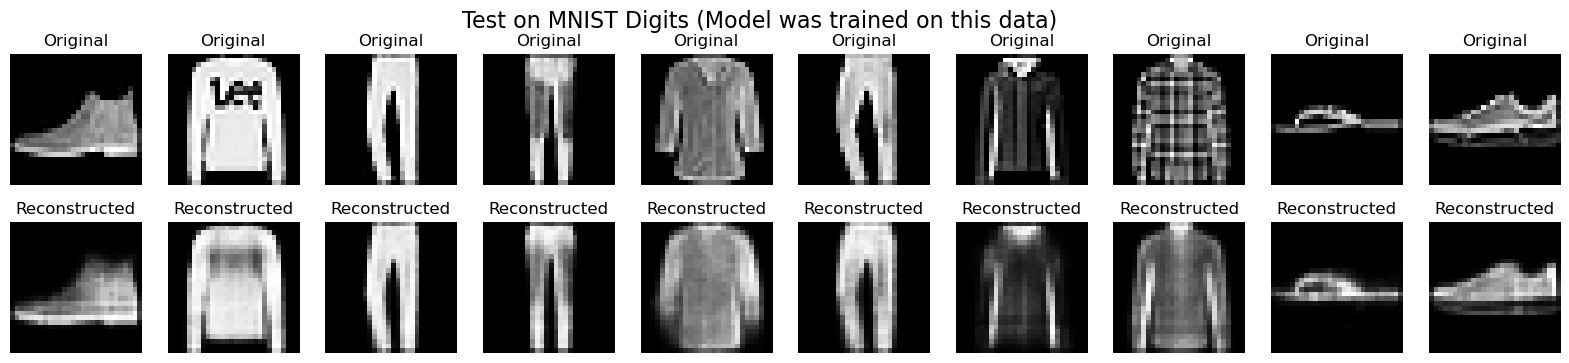

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import os
from PIL import Image
import random

# ===================================================================
# 1. SETUP AND TRAIN THE AUTOENCODER ON MNIST DIGITS
# ===================================================================

# Load MNIST dataset
(x_train, _), (x_test, _) = tf.keras.datasets.fashion_mnist.load_data()

# Normalize and flatten
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train.reshape((len(x_train), -1))
x_test = x_test.reshape((len(x_test), -1))

# Latent space size
latent_dim = 64

# Encoder
encoder = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(latent_dim, activation='relu')
])

# Decoder
decoder = models.Sequential([
    layers.Input(shape=(latent_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(784, activation='sigmoid')
])

# Autoencoder
autoencoder = models.Sequential([encoder, decoder])
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

# Train
print("--- Training Autoencoder on MNIST Digits ---")
autoencoder.fit(x_train, x_train,
                epochs=10,
                batch_size=256,
                shuffle=True,
                validation_data=(x_test, x_test))

# ===================================================================
# 2. TEST WITH YOUR LOCAL ALPHABET DATASET
# ===================================================================
print("\n--- Loading Local Alphabet Dataset for Testing ---")

base_path = ""
alphabet_images = []
alphabet_labels = []

if not os.path.exists(base_path):
    print(f"Error: Directory not found at '{base_path}'")
else:
    for letter in "ABCDEFGHIJKLMNOPQRSTUVWXYZ":
        folder_path = os.path.join(base_path, letter)
        if os.path.exists(folder_path):
            for file_name in os.listdir(folder_path):
                if file_name.endswith(('.png', '.jpg', '.jpeg')):
                    file_path = os.path.join(folder_path, file_name)
                    img = Image.open(file_path).convert('L')
                    img = img.resize((28, 28))
                    img_array = np.array(img).astype("float32") / 255.0
                    alphabet_images.append(img_array.flatten())
                    alphabet_labels.append(letter)

    if not alphabet_images:
        print("No letter images were found.")
    else:
        x_test_letters = np.array(alphabet_images)
        print(f"Successfully loaded {len(x_test_letters)} letter images.")

        sample_indices = random.sample(range(len(x_test_letters)), 10)
        sample_images = x_test_letters[sample_indices]
        sample_labels = [alphabet_labels[i] for i in sample_indices]

        encoded_letters = encoder.predict(sample_images)
        decoded_letters = decoder.predict(encoded_letters)

        plt.figure(figsize=(20, 5))
        plt.suptitle("Test on Your Alphabet Data (Model has NOT seen letters)", fontsize=16)
        for i in range(10):
            # Original Letter
            ax = plt.subplot(2, 10, i + 1)
            plt.imshow(sample_images[i].reshape(28, 28), cmap='gray')
            plt.title(f"Original\n{sample_labels[i]}")
            plt.axis("off")
            # Reconstructed Letter
            ax = plt.subplot(2, 10, i + 1 + 10)
            plt.imshow(decoded_letters[i].reshape(28, 28), cmap='gray')
            plt.title("Reconstructed")
            plt.axis("off")
        plt.show()

# ===================================================================
# 3. NEW: TEST WITH MNIST DIGIT DATASET
# ===================================================================
print("\n--- Testing with MNIST Digit Test Set ---")

# Use the model to reconstruct the MNIST test digits
encoded_imgs = encoder.predict(x_test)
decoded_imgs = decoder.predict(encoded_imgs)

# Show original vs reconstructed
plt.figure(figsize=(20, 4))
plt.suptitle("Test on MNIST Digits (Model was trained on this data)", fontsize=16)
n = 10
for i in range(n):
    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis("off")

    # Reconstructed
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis("off")

plt.show()